# v2 training curves and validation results
Training curves (train loss, validation cross-entropy, validation OA, validation mIoU per epoch) of the five final model variants (100 epochs each) and of the four label/input ablation runs (60 epochs each). The per-epoch logs were saved by the training notebooks (`v2-03-train-*`) in `training_logs/`.


In [1]:
import pandas as pd, matplotlib.pyplot as plt
D = "training_logs/"
print(pd.read_csv(D + "validation_summary.csv").to_string(index=False))
print()
print(pd.read_csv(D + "ablation_summary.csv").to_string(index=False))

                      run  best_epoch  val_mIoU  val_OA  final_train_loss  epochs
           U-Net, scratch          92     0.540   0.716             0.817     100
      DeepLabV3+, scratch          83     0.536   0.722             0.683     100
U-Net, pretrained (final)          84     0.567   0.738             0.701     100
   DeepLabV3+, pretrained          77     0.558   0.735             0.643     100
 FPN-ResNet50, pretrained          93     0.566   0.742             0.555     100

                               run  epochs  best_epoch  val_mIoU_own_labels  val_mIoU_vs_consensus  val_OA  final_epoch_mIoU_vs_consensus
                  Consensus labels      60          60                0.518                  0.518   0.700                          0.518
                 WorldCover labels      60          60                0.462                  0.491   0.664                          0.491
              Dynamic World labels      60          49                0.483                  

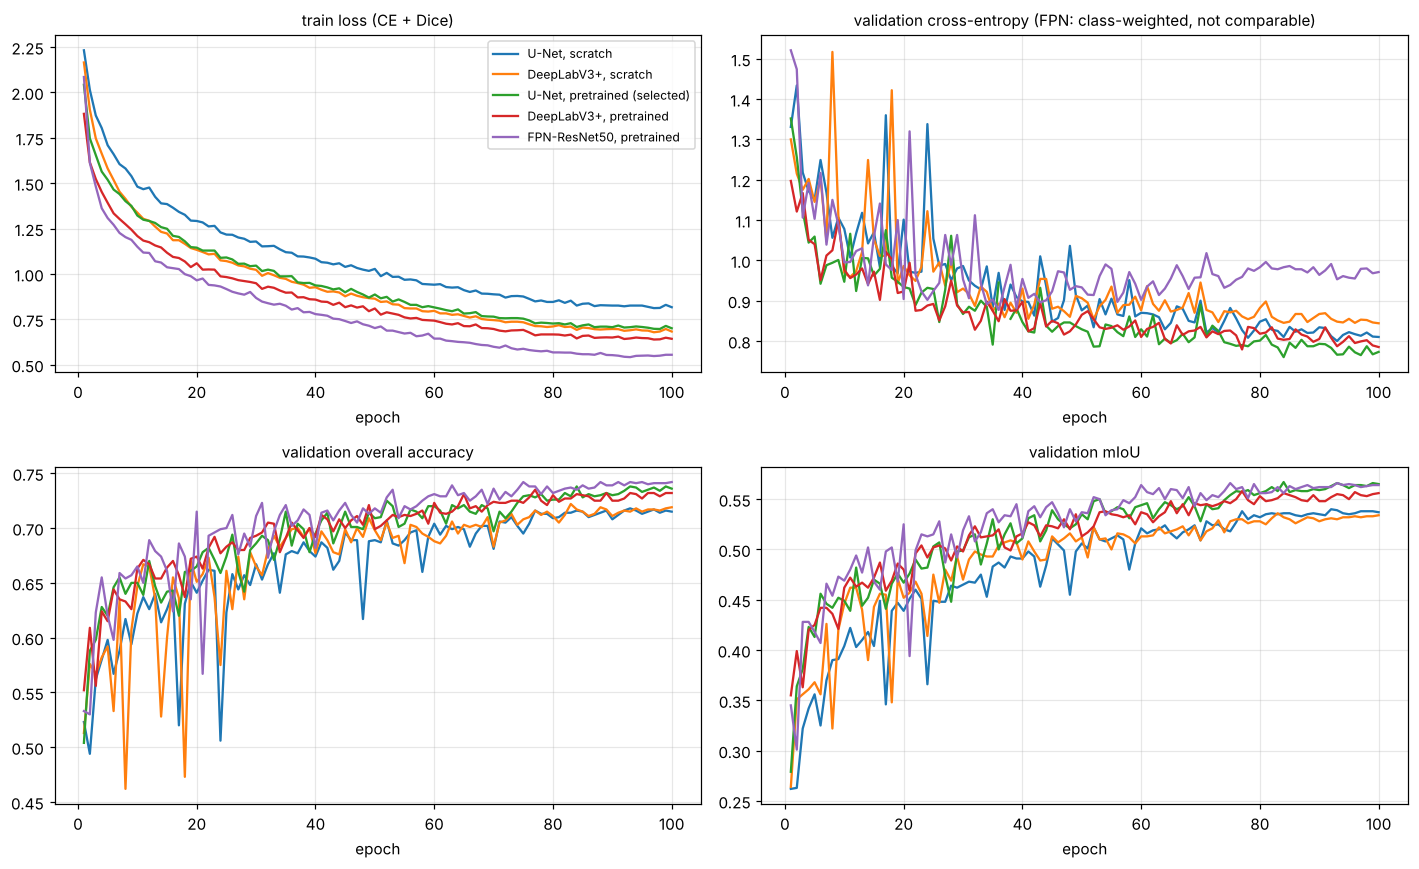

In [2]:
runs = {"U-Net, scratch": "E3_unet_scratch", "DeepLabV3+, scratch": "E3_deeplab_scratch",
        "U-Net, pretrained (selected)": "E4_unet_pretrained", "DeepLabV3+, pretrained": "E4_deeplab_pretrained",
        "FPN-ResNet50, pretrained": "E5_fpn_r50_pretrained"}
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for name, f in runs.items():
    d = pd.read_csv(D + f"training_log_{f}.csv")
    ax[0,0].plot(d.epoch, d.train_loss, label=name); ax[0,1].plot(d.epoch, d.val_CE, label=name)
    ax[1,0].plot(d.epoch, d.val_OA, label=name); ax[1,1].plot(d.epoch, d.val_mIoU, label=name)
for a, t in zip(ax.flat, ["train loss (CE + Dice)", "validation cross-entropy (FPN: class-weighted, not comparable)", "validation overall accuracy", "validation mIoU"]):
    a.set_title(t, fontsize=10); a.set_xlabel("epoch"); a.grid(alpha=.3)
ax[0,0].legend(fontsize=8); plt.tight_layout(); plt.show()

In [3]:
summ = pd.read_csv(D + "validation_summary.csv")
for (name, f), be in zip(runs.items(), summ.best_epoch):
    d = pd.read_csv(D + f"training_log_{f}.csv"); b = d[d.epoch == be].iloc[0]
    print(f"{name:32s} best epoch {int(be):3d} | val mIoU {b.val_mIoU:.3f} | val OA {b.val_OA:.3f} | last epoch mIoU {d.val_mIoU.iloc[-1]:.3f}")
print("(best epoch = the epoch kept by the training notebook, chosen on unrounded validation mIoU; the logged values are rounded to 3 decimals)")

U-Net, scratch                   best epoch  92 | val mIoU 0.540 | val OA 0.716 | last epoch mIoU 0.537
DeepLabV3+, scratch              best epoch  83 | val mIoU 0.536 | val OA 0.722 | last epoch mIoU 0.534
U-Net, pretrained (selected)     best epoch  84 | val mIoU 0.567 | val OA 0.738 | last epoch mIoU 0.565
DeepLabV3+, pretrained           best epoch  77 | val mIoU 0.558 | val OA 0.735 | last epoch mIoU 0.556
FPN-ResNet50, pretrained         best epoch  93 | val mIoU 0.566 | val OA 0.742 | last epoch mIoU 0.564
(best epoch = the epoch kept by the training notebook, chosen on unrounded validation mIoU; the logged values are rounded to 3 decimals)


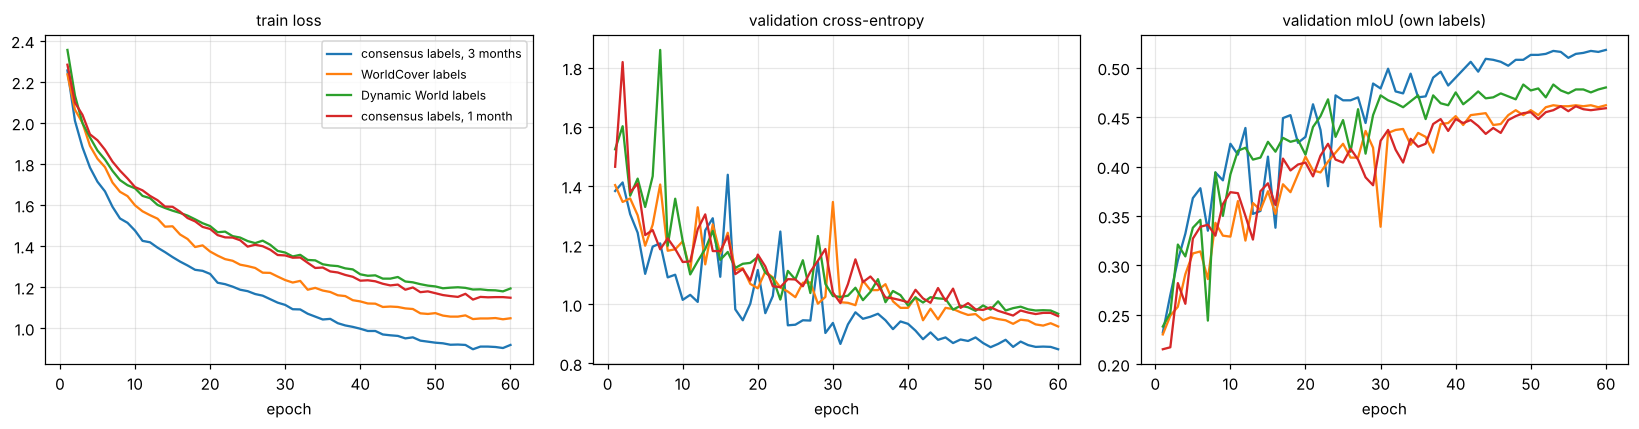

In [4]:
abl = {"consensus labels, 3 months": "E_consensus", "WorldCover labels": "E_worldcover",
       "Dynamic World labels": "E_dynworld", "consensus labels, 1 month": "E_1month"}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for name, f in abl.items():
    d = pd.read_csv(D + f"training_log_{f}.csv")
    ax[0].plot(d.epoch, d.train_loss, label=name); ax[1].plot(d.epoch, d.val_CE, label=name); ax[2].plot(d.epoch, d.val_mIoU, label=name)
for a, t in zip(ax, ["train loss", "validation cross-entropy", "validation mIoU (own labels)"]):
    a.set_title(t, fontsize=10); a.set_xlabel("epoch"); a.grid(alpha=.3)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()